# SFT with lora for ASR corrections (Text)

## Install dependencies

In [ ]:
!pip install -q -U transformers datasets bitsandbytes  trl peft accelerate huggingface_hub

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.3/12.3 MB 141.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 559.1/559.1 kB 46.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 62.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 925.0/925.0 kB 64.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 832.9/832.9 kB 55.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 394.3/394.3 kB 36.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 846.4/846.4 kB 62.5 MB/s eta 0:00:00


In [ ]:
# !nvidia-smi #check GPU access/availability

In [ ]:
# login to HF required to access certain models
from huggingface_hub import notebook_login

notebook_login()

## Import libraries

In [ ]:
import json
import os
import platform
import random
import pandas as pd
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from datasets import Dataset, DatasetDict, load_dataset
from peft import LoraConfig, get_peft_model, prepare_model_for_kbit_training
from transformers import (
    AutoModelForCausalLM,
    AutoTokenizer,
    BitsAndBytesConfig,
    DataCollatorForSeq2Seq,
    set_seed,
)
from trl import SFTConfig, SFTTrainer


In [ ]:
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
set_seed(SEED)

# print("Python platform:", platform.platform())
# print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
# print("MPS available:", torch.backends.mps.is_available() if hasattr(torch.backends, "mps") else False)

CUDA available: True


## Load data

In [ ]:
from google.colab import drive
drive.mount('/content/gdrive')

Mounted at /content/gdrive


In [ ]:
DATA_PATH = '/content/gdrive/My Drive/BiorampProjects/data/sample_data.jsonl'
raw_dataset = load_dataset(
    "json",
    data_files={"train": str(DATA_PATH)},
)["train"]

print(raw_dataset)
print("columns:", raw_dataset.column_names)
raw_dataset[0]

Generating train split: 0 examples [00:00, ? examples/s]

Dataset({
    features: ['id', 'session_id', 'source_model', 'domain', 'context', 'hypothesis', 'reference', 'errors', 'source_file', 'provenance', 'annotation_summary'],
    num_rows: 8
})
columns: ['id', 'session_id', 'source_model', 'domain', 'context', 'hypothesis', 'reference', 'errors', 'source_file', 'provenance', 'annotation_summary']


{'id': 'gemma3n::RES0199',
 'session_id': 'RES0199',
 'source_model': 'gemma3n',
 'domain': 'clinical_dialogue',
 'context': [{'speaker': 'unknown',
   'text': 'what brings you in hi i just came in today i have been having just been feeling really sick over the last three or four days it started with just like a headache and cough four days ago and then i started getting some nausea and vomiting few days back as well as diarrhea okay so the headache and cough started first you said right yeah okay let us talk about the headache first that came on four days ago has it been persistent or does it come and go it is been pretty persistent besides when i take some tylenol okay and does anything make it better or worse just a tylenol nothing really yeah it is pretty constant okay and have a an and sorry where exactly is it is it on it is like at the top of your head temples forehead it is kind of like my forehead in the top of my head on both sides okay and does it radiate your neck or anywhe

### Validate and inspect data

In [ ]:
REQUIRED_FIELDS = {"id", "session_id", "source_model", "domain", "hypothesis", "reference", "errors", "annotation_summary"}


def max_token_run(text):
    words = text.split()
    if not words:
        return 0, None
    best_count = current_count = 1
    best_word = current_word = words[0]
    for word in words[1:]:
        if word == current_word:
            current_count += 1
        else:
            current_word, current_count = word, 1
        if current_count > best_count:
            best_count, best_word = current_count, current_word
    return best_count, best_word


rows = []
invalid_indices = []
for index, record in enumerate(raw_dataset):
    missing = REQUIRED_FIELDS - set(record)
    if missing or not str(record.get("id", "")).strip() or not str(record.get("session_id", "")).strip() \
            or not str(record.get("hypothesis", "")).strip() or not str(record.get("reference", "")).strip():
        invalid_indices.append((index, sorted(missing)))
        continue
    max_run, repeated_word = max_token_run(record["hypothesis"])
    rows.append({
        "id": record["id"],
        "session_id": record["session_id"],
        "source_model": record["source_model"],
        "hyp_words": len(record["hypothesis"].split()),
        "ref_words": len(record["reference"].split()),
        "parsed_edits": record["annotation_summary"]["parsed_edits"],
        "annotated_edits": record["annotation_summary"]["annotated_edits"],
        "coverage": record["annotation_summary"]["coverage"],
        "max_severity": record["annotation_summary"]["max_rated_severity"],
        "max_repetition_run": max_run,
        "repeated_word": repeated_word,
    })

assert not invalid_indices, f"Invalid records: {invalid_indices}"
summary_df = pd.DataFrame(rows)
display(summary_df)
print("records:", len(summary_df))
print("unique sessions:", summary_df.session_id.nunique())
print("source models:", sorted(summary_df.source_model.unique()))
print("weighted annotation coverage:", summary_df.annotated_edits.sum() / summary_df.parsed_edits.sum())

pathological_ids = summary_df.loc[summary_df.max_repetition_run >= 20, "id"].tolist()
print("pathological repetition records:", pathological_ids)
print("These records remain visible for audit; DROP_PATHOLOGICAL controls whether they enter training.")

,id,session_id,source_model,hyp_words,ref_words,parsed_edits,annotated_edits,coverage,max_severity,max_repetition_run,repeated_word
0,gemma3n::RES0199,RES0199,gemma3n,1158,1143,87,13,0.149425,2,2,okay
1,gemma3n::day2_consultation06,day2_consultation06,gemma3n,1875,1934,198,7,0.035354,2,3,i
2,gemma3n::day3_consultation04,day3_consultation04,gemma3n,1089,1112,129,9,0.069767,2,2,hi
3,gemma3n::day5_consultation04,day5_consultation04,gemma3n,1486,1269,161,21,0.130435,3,220,chair
4,nemotron35::day1_consultation01,day1_consultation01,nemotron35,1274,1364,180,51,0.283333,2,12,but
5,phi4::46aacf84-fdd1-490b-a857-633d2e7763a0_7d4...,46aacf84-fdd1-490b-a857-633d2e7763a0_7d4de4c9d...,phi4,688,696,54,34,0.629630,3,2,you
6,qwen3::day4_consultation08,day4_consultation08,qwen3,1081,1692,88,10,0.113636,3,3,yeah
7,qwen3::day5_consultation02,day5_consultation02,qwen3,808,1092,36,9,0.250000,3,2,you


records: 8
unique sessions: 8
source models: ['gemma3n', 'nemotron35', 'phi4', 'qwen3']
weighted annotation coverage: 0.16505894962486603
pathological repetition records: ['gemma3n::day5_consultation04']
These records remain visible for audit; DROP_PATHOLOGICAL controls whether they enter training.


## Configure and Load Qwen3-0.6B

4-bit QLoRA is enabled only when CUDA is available.

In [ ]:
MODEL_NAME = "Qwen/Qwen3-0.6B"
USE_4BIT = torch.cuda.is_available()

if torch.cuda.is_available():
    COMPUTE_DTYPE = torch.bfloat16 if torch.cuda.is_bf16_supported() else torch.float16
elif hasattr(torch.backends, "mps") and torch.backends.mps.is_available():
    COMPUTE_DTYPE = torch.float16
else:
    COMPUTE_DTYPE = torch.float32

model_kwargs = {
    "trust_remote_code": True,
    "torch_dtype": COMPUTE_DTYPE,
    "device_map": "auto",
}

if USE_4BIT:
    model_kwargs["quantization_config"] = BitsAndBytesConfig(
        load_in_4bit=True,
        bnb_4bit_quant_type="nf4",
        bnb_4bit_use_double_quant=True,
        bnb_4bit_compute_dtype=COMPUTE_DTYPE,
    )

model = AutoModelForCausalLM.from_pretrained(MODEL_NAME, **model_kwargs)
tok_kwargs = {
    "padding_side": "right",
    "trust_remote_code": True,
}
tok_kwargs["model_max_length"] = 8192
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME, **tok_kwargs)

if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

# Adjust maximum position embeddings to match our maximum sequence lengths
model.config.max_position_embeddings = 8192
model.config.pad_token_id = tokenizer.pad_token_id
model.config.use_cache = False

print("model:", MODEL_NAME)
print("dtype:", COMPUTE_DTYPE)
print("4-bit QLoRA:", USE_4BIT)
print("model device:", next(model.parameters()).device)

Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

model: Qwen/Qwen3-0.6B
dtype: torch.bfloat16
4-bit QLoRA: True
model device: cuda:0


In [ ]:
model

Qwen3ForCausalLM(
  (model): Qwen3Model(
    (embed_tokens): Embedding(151936, 1024)
    (layers): ModuleList(
      (0-27): 28 x Qwen3DecoderLayer(
        (self_attn): Qwen3Attention(
          (q_proj): Linear4bit(in_features=1024, out_features=2048, bias=False)
          (k_proj): Linear4bit(in_features=1024, out_features=1024, bias=False)
          (v_proj): Linear4bit(in_features=1024, out_features=1024, bias=False)
          (o_proj): Linear4bit(in_features=2048, out_features=1024, bias=False)
          (q_norm): Qwen3RMSNorm((128,), eps=1e-06)
          (k_norm): Qwen3RMSNorm((128,), eps=1e-06)
        )
        (mlp): Qwen3MLP(
          (gate_proj): Linear4bit(in_features=1024, out_features=3072, bias=False)
          (up_proj): Linear4bit(in_features=1024, out_features=3072, bias=False)
          (down_proj): Linear4bit(in_features=3072, out_features=1024, bias=False)
          (act_fn): SiLUActivation()
        )
        (input_layernorm): Qwen3RMSNorm((1024,), eps=1e-06)
 

## Inspect the Qwen Tokenizer and Chat Template

Qwen's built-in chat template and existing special tokens are used directly. No custom role tokens are added and model embeddings are not resized.

In [ ]:
print("special tokens:", tokenizer.all_special_tokens)
print("BOS:", tokenizer.bos_token, tokenizer.bos_token_id)
print("EOS:", tokenizer.eos_token, tokenizer.eos_token_id)
print("PAD:", tokenizer.pad_token, tokenizer.pad_token_id)
print("vocabulary size:", len(tokenizer))
print("model vocabulary size:", model.config.vocab_size)
# print("\nchat template preview:\n", tokenizer.chat_template[:1200], "...") #Uncomment to view chat_tempplate

special tokens: ['<|im_end|>', '<|endoftext|>', '<|im_start|>', '<|object_ref_start|>', '<|object_ref_end|>', '<|box_start|>', '<|box_end|>', '<|quad_start|>', '<|quad_end|>', '<|vision_start|>', '<|vision_end|>', '<|vision_pad|>', '<|image_pad|>', '<|video_pad|>']
BOS: None None
EOS: <|im_end|> 151645
PAD: <|endoftext|> 151643
vocabulary size: 151669
model vocabulary size: 151936


## Create SFT Messages from data

The visible conversation follows the system/user/assistant format.

Note*: As discussed, I designed the `context` based on the prior utterances, we can adjust as needed. For now, I will not be using the context, so `USE_CONTEXT` is set to `FALSE`

In [ ]:
SYSTEM_MESSAGE = (
    "You are a conservative clinical ASR correction system. "
    "Correct only recognition errors supported by the supplied transcript and safe dialogue context. "
    "Preserve clinically correct wording, especially negations, medication names, doses, measurements, "
    "anatomy, symptoms, and temporal expressions. Do not add facts that are absent from the input. "
    "Return only the corrected transcript, with no explanation."
)

USE_CONTEXT = False
DROP_PATHOLOGICAL = True


def format_context(context):
    return "\n".join(f"{turn['speaker']}: {turn['text']}" for turn in context)


def create_messages(example):
    user_parts = [f"Domain: {example['domain']}"]
    if USE_CONTEXT:
        user_parts.append("Dialogue context:\n" + format_context(example.get("context", [])))
    user_parts.extend([
        "Current ASR hypothesis:\n" + example["hypothesis"],
        "Task: Return the corrected transcript only.",
    ])
    messages = [
        {"role": "system", "content": SYSTEM_MESSAGE},
        {"role": "user", "content": "\n\n".join(user_parts)},
        {"role": "assistant", "content": example["reference"]},
    ]
    return {"messages": messages}


working_dataset = raw_dataset
if DROP_PATHOLOGICAL and pathological_ids:
    pathological_set = set(pathological_ids)
    working_dataset = working_dataset.filter(lambda example: example["id"] not in pathological_set)

message_dataset = working_dataset.map(create_messages)
print("records used:", len(message_dataset), "of", len(raw_dataset))
message_dataset[0]["messages"]

Filter:   0%|          | 0/8 [00:00<?, ? examples/s]

Map:   0%|          | 0/7 [00:00<?, ? examples/s]

records used: 7 of 8


[{'content': 'You are a conservative clinical ASR correction system. Correct only recognition errors supported by the supplied transcript and safe dialogue context. Preserve clinically correct wording, especially negations, medication names, doses, measurements, anatomy, symptoms, and temporal expressions. Do not add facts that are absent from the input. Return only the corrected transcript, with no explanation.',
  'role': 'system'},
 {'content': 'Domain: clinical_dialogue\n\nCurrent ASR hypothesis:\nwhat brings you in hi i just came in today i have been having just been feeling really sick over the last three or four days it started with just a like a headache and cough four days ago and then i started getting some nausea and vomiting a few days back as well as diarrhea oh okay so the headache and cough started first you said right yeah okay let us talk about the headache first that is came on four days ago has it been persistent or does it come and go it is been pretty persistent be



```
# This is formatted as code
```

## Apply the Qwen Chat Template

Setting the training text to use the model's own template with `enable_thinking=False`. The reference appears only in the assistant segment. The prefix length is retained so prompt tokens can be masked from the loss.

In [ ]:
def apply_qwen_template(example):
    prompt_messages = example["messages"][:-1]
    prompt_text = tokenizer.apply_chat_template(
        prompt_messages,
        tokenize=False,
        add_generation_prompt=True,
        enable_thinking=False,
    )
    text = tokenizer.apply_chat_template(
        example["messages"],
        tokenize=False,
        add_generation_prompt=False,
        enable_thinking=False,
    )
    assistant_text = example["messages"][-1]["content"]
    assert assistant_text == example["reference"]
    assert text.startswith(prompt_text), "Prompt/full chat templates are inconsistent"
    return {"text": text, "prompt_text": prompt_text}


formatted_dataset = message_dataset.map(apply_qwen_template)
example = formatted_dataset[0]
print(example["text"][:2500])
print("\nassistant begins at character:", len(example["prompt_text"]))
print("context included in visible prompt:", USE_CONTEXT)

Map:   0%|          | 0/7 [00:00<?, ? examples/s]

<|im_start|>system
You are a conservative clinical ASR correction system. Correct only recognition errors supported by the supplied transcript and safe dialogue context. Preserve clinically correct wording, especially negations, medication names, doses, measurements, anatomy, symptoms, and temporal expressions. Do not add facts that are absent from the input. Return only the corrected transcript, with no explanation.<|im_end|>
<|im_start|>user
Domain: clinical_dialogue

Current ASR hypothesis:
what brings you in hi i just came in today i have been having just been feeling really sick over the last three or four days it started with just a like a headache and cough four days ago and then i started getting some nausea and vomiting a few days back as well as diarrhea oh okay so the headache and cough started first you said right yeah okay let us talk about the headache first that is came on four days ago has it been persistent or does it come and go it is been pretty persistent besides wh

## Dataset Splits

This is just an example. We need a better data split. I will propose that the golden dataset used to establish the IRR be used as part of the test script

In [ ]:
session_ids = sorted(set(formatted_dataset["session_id"]))
rng = random.Random(SEED)
rng.shuffle(session_ids)

assert len(session_ids) >= 3, "Need at least three independent sessions for train/validation/test"
validation_sessions = set(session_ids[:1])
test_sessions = set(session_ids[1:2])
train_sessions = set(session_ids[2:])


def indices_for_sessions(dataset, allowed_sessions):
    return [index for index, session_id in enumerate(dataset["session_id"]) if session_id in allowed_sessions]


splits = DatasetDict({
    "train": formatted_dataset.select(indices_for_sessions(formatted_dataset, train_sessions)),
    "validation": formatted_dataset.select(indices_for_sessions(formatted_dataset, validation_sessions)),
    "test": formatted_dataset.select(indices_for_sessions(formatted_dataset, test_sessions)),
})

assert train_sessions.isdisjoint(validation_sessions)
assert train_sessions.isdisjoint(test_sessions)
assert validation_sessions.isdisjoint(test_sessions)

split_rows = []
for split_name, split in splits.items():
    for example in split:
        split_rows.append({
            "split": split_name,
            "id": example["id"],
            "session_id": example["session_id"],
            "source_model": example["source_model"],
            "max_severity": example["annotation_summary"]["max_rated_severity"],
            "coverage": example["annotation_summary"]["coverage"],
        })

display(pd.DataFrame(split_rows))
print(splits)
print("train sessions:", sorted(train_sessions))
print("validation sessions:", sorted(validation_sessions))
print("test sessions:", sorted(test_sessions))

,split,id,session_id,source_model,max_severity,coverage
0,train,gemma3n::day3_consultation04,day3_consultation04,gemma3n,2,0.069767
1,train,nemotron35::day1_consultation01,day1_consultation01,nemotron35,2,0.283333
2,train,phi4::46aacf84-fdd1-490b-a857-633d2e7763a0_7d4...,46aacf84-fdd1-490b-a857-633d2e7763a0_7d4de4c9d...,phi4,3,0.629630
3,train,qwen3::day4_consultation08,day4_consultation08,qwen3,3,0.113636
4,train,qwen3::day5_consultation02,day5_consultation02,qwen3,3,0.250000
5,validation,gemma3n::RES0199,RES0199,gemma3n,2,0.149425
6,test,gemma3n::day2_consultation06,day2_consultation06,gemma3n,2,0.035354


DatasetDict({
    train: Dataset({
        features: ['id', 'session_id', 'source_model', 'domain', 'context', 'hypothesis', 'reference', 'errors', 'source_file', 'provenance', 'annotation_summary', 'messages', 'text', 'prompt_text'],
        num_rows: 5
    })
    validation: Dataset({
        features: ['id', 'session_id', 'source_model', 'domain', 'context', 'hypothesis', 'reference', 'errors', 'source_file', 'provenance', 'annotation_summary', 'messages', 'text', 'prompt_text'],
        num_rows: 1
    })
    test: Dataset({
        features: ['id', 'session_id', 'source_model', 'domain', 'context', 'hypothesis', 'reference', 'errors', 'source_file', 'provenance', 'annotation_summary', 'messages', 'text', 'prompt_text'],
        num_rows: 1
    })
})
train sessions: ['46aacf84-fdd1-490b-a857-633d2e7763a0_7d4de4c9d3488a4bbd35634cbd3a2b66_l1RjPEwA', 'day1_consultation01', 'day3_consultation04', 'day4_consultation08', 'day5_consultation02']
validation sessions: ['RES0199']
test sessio

## **Training**

### Configure LoRA Adapters

For this test, I am freezing all main modules, we can figure condifure which specific modules to freeze later

In [ ]:
if USE_4BIT:
    model = prepare_model_for_kbit_training(model, use_gradient_checkpointing=True)

lora_config = LoraConfig(
    r=16,
    lora_alpha=32,
    target_modules=[
        "q_proj", "k_proj", "v_proj", "o_proj",
        "gate_proj", "up_proj", "down_proj",
    ],
    lora_dropout=0.05,
    bias="none",
    task_type="CAUSAL_LM",
)

model = get_peft_model(model, lora_config)
model.print_trainable_parameters()

trainable params: 10,092,544 || all params: 606,142,464 || trainable%: 1.6650


## Configure the SFT Trainer


In [ ]:
MAX_SEQUENCE_LENGTH = 8192


def tokenize_for_completion_loss(example):
    full_ids = tokenizer(example["text"], add_special_tokens=False)["input_ids"]
    prompt_ids = tokenizer(example["prompt_text"], add_special_tokens=False)["input_ids"]
    if len(full_ids) > MAX_SEQUENCE_LENGTH:
        raise ValueError(
            f"{example['id']} needs {len(full_ids)} tokens, above MAX_SEQUENCE_LENGTH={MAX_SEQUENCE_LENGTH}. "
            "Increase the limit or create alignment-safe chunks; do not silently truncate the reference."
        )
    assert full_ids[:len(prompt_ids)] == prompt_ids, f"Prompt token mismatch for {example['id']}"
    labels = [-100] * len(prompt_ids) + full_ids[len(prompt_ids):]
    assert any(label != -100 for label in labels), f"No assistant labels for {example['id']}"
    return {
        "input_ids": full_ids,
        "attention_mask": [1] * len(full_ids),
        "labels": labels,
    }


tokenized_splits = DatasetDict({
    name: split.map(
        tokenize_for_completion_loss,
        remove_columns=split.column_names,
        desc=f"Tokenizing {name}",
    )
    for name, split in splits.items()
})

Tokenizing train:   0%|          | 0/5 [00:00<?, ? examples/s]

Tokenizing validation:   0%|          | 0/1 [00:00<?, ? examples/s]

Tokenizing test:   0%|          | 0/1 [00:00<?, ? examples/s]

In [ ]:
tokenized_splits = DatasetDict({
    name: split.map(
        tokenize_for_completion_loss,
        remove_columns=split.column_names,
        desc=f"Tokenizing {name}",
    )
    for name, split in splits.items()
})

length_rows = []
for split_name, split in tokenized_splits.items():
    for index, input_ids in enumerate(split["input_ids"]):
        length_rows.append({"split": split_name, "index": index, "tokens": len(input_ids)})
length_df = pd.DataFrame(length_rows)
display(length_df.sort_values("tokens", ascending=False))
print("maximum sequence length:", length_df.tokens.max())

# The tokenizer pads inputs/attention masks and pads labels with -100.
data_collator = DataCollatorForSeq2Seq(
    tokenizer=tokenizer,
    padding=True,
    label_pad_token_id=-100,
    return_tensors="pt",
)

from trl import SFTConfig, SFTTrainer

OUTPUT_DIR = Path("/Users/gloriakatuka/BiorampProjects/SFT/outputs/qwen3-0.6b-clinical-asr-sft")
BF16 = torch.cuda.is_available() and torch.cuda.is_bf16_supported()
FP16 = torch.cuda.is_available() and not BF16

sft_config = SFTConfig(
    output_dir=str(OUTPUT_DIR),
    num_train_epochs=1,
    per_device_train_batch_size=1,
    per_device_eval_batch_size=1,
    gradient_accumulation_steps=4,
    learning_rate=2e-4,
    weight_decay=0.01,
    warmup_steps=5,
    lr_scheduler_type="cosine",
    logging_steps=1,
    eval_strategy="steps",
    eval_steps=1,
    save_strategy="steps",
    save_steps=1,
    save_total_limit=2,
    max_length=MAX_SEQUENCE_LENGTH,
    gradient_checkpointing=USE_4BIT,
    bf16=BF16,
    fp16=FP16,
    report_to="none",
    seed=SEED,
    data_seed=SEED,
    remove_unused_columns=False,
)

trainer = SFTTrainer(
    model=model,
    args=sft_config,
    train_dataset=tokenized_splits["train"],
    eval_dataset=tokenized_splits["validation"],
    processing_class=tokenizer,
    data_collator=data_collator,
)

batch = data_collator([tokenized_splits["train"][0]])
print({key: tuple(value.shape) for key, value in batch.items()})
print("assistant tokens contributing to loss:", int(batch["labels"].ne(-100).sum()))

,split,index,tokens
6,test,0,4041
3,train,3,2949
1,train,1,2844
5,validation,0,2502
0,train,0,2482
4,train,4,2068
2,train,2,1554


maximum sequence length: 4041


Truncating train dataset:   0%|          | 0/5 [00:00<?, ? examples/s]

Dropping fully masked examples from train dataset:   0%|          | 0/5 [00:00<?, ? examples/s]

Truncating eval dataset:   0%|          | 0/1 [00:00<?, ? examples/s]

Dropping fully masked examples from eval dataset:   0%|          | 0/1 [00:00<?, ? examples/s]

{'input_ids': (1, 2482), 'attention_mask': (1, 2482), 'labels': (1, 2482)}
assistant tokens contributing to loss: 1200


In [ ]:
train_result = trainer.train()
train_result

Step,Training Loss,Validation Loss,Entropy,Num Tokens,Mean Token Accuracy
1,1.383002,0.667248,0.352234,20950.000000,0.888047
2,1.275917,0.639538,0.389944,23794.000000,0.891414


TrainOutput(global_step=2, training_loss=1.3294594287872314, metrics={'train_runtime': 4.6315, 'train_samples_per_second': 1.08, 'train_steps_per_second': 0.432, 'total_flos': 32161873920000.0, 'train_loss': 1.3294594287872314, 'epoch': 1.0})

### Inspect the training

,loss,grad_norm,learning_rate,entropy,num_tokens,mean_token_accuracy,epoch,step,eval_loss,eval_runtime,eval_samples_per_second,eval_steps_per_second,eval_entropy,eval_num_tokens,eval_mean_token_accuracy,train_runtime,train_samples_per_second,train_steps_per_second,total_flos,train_loss
0,1.383002,1.875,0.00000,0.701504,20950.0,0.789488,0.8,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN,0.8,1,0.667248,0.1575,6.348,6.348,0.352234,20950.0,0.888047,NaN,NaN,NaN,NaN,NaN
2,1.275917,2.750,0.00004,0.645941,23794.0,0.787070,1.0,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,NaN,NaN,NaN,1.0,2,0.639538,0.1550,6.451,6.451,0.389944,23794.0,0.891414,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,NaN,NaN,NaN,NaN,1.0,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4.6315,1.08,0.432,3.216187e+13,1.329459


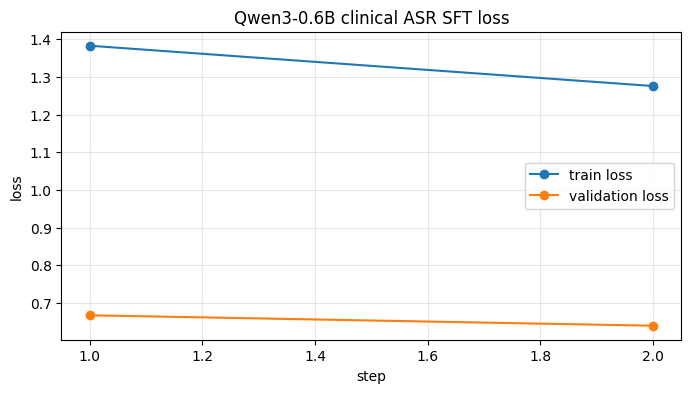

,value
train_runtime,4.631500e+00
train_samples_per_second,1.080000e+00
train_steps_per_second,4.320000e-01
total_flos,3.216187e+13
train_loss,1.329459e+00
epoch,1.000000e+00
best_checkpoint,NaN
global_step,2.000000e+00
cuda_peak_memory_GB,2.918577e+00


In [ ]:
history_df = pd.DataFrame(trainer.state.log_history)
display(history_df)

fig, ax = plt.subplots(figsize=(8, 4))
if "loss" in history_df:
    train_history = history_df.dropna(subset=["loss"])
    ax.plot(train_history["step"], train_history["loss"], marker="o", label="train loss")
if "eval_loss" in history_df:
    eval_history = history_df.dropna(subset=["eval_loss"])
    ax.plot(eval_history["step"], eval_history["eval_loss"], marker="o", label="validation loss")
ax.set_xlabel("step")
ax.set_ylabel("loss")
ax.set_title("Qwen3-0.6B clinical ASR SFT loss")
ax.grid(alpha=0.3)
ax.legend()
plt.show()

metrics = dict(train_result.metrics)
metrics.update({
    "best_checkpoint": trainer.state.best_model_checkpoint,
    "global_step": trainer.state.global_step,
})
if torch.cuda.is_available():
    metrics["cuda_peak_memory_GB"] = torch.cuda.max_memory_allocated() / 1024**3

display(pd.Series(metrics, name="value").to_frame())

### Test the model

In [ ]:
test_sample = splits["validation"][0]
prompt_messages = test_sample["messages"][:-1]
prompt_text = tokenizer.apply_chat_template(
    prompt_messages,
    tokenize=False,
    add_generation_prompt=True,
    enable_thinking=False,
)

model_inputs = tokenizer(prompt_text, return_tensors="pt", add_special_tokens=False)
model_device = next(trainer.model.parameters()).device
model_inputs = {key: value.to(model_device) for key, value in model_inputs.items()}

# Calculate a safe maximum length
max_new_tokens = min(2500, max(256, int(1.2 * len(test_sample["reference"].split()))))

trainer.model.eval()
with torch.no_grad():
    generated_ids = trainer.model.generate(
        **model_inputs,
        max_new_tokens=max_new_tokens,
        do_sample=True,             # Enabled sampling to prevent premature cutoff
        temperature=0.3,            # Low temperature for conservative corrections
        top_p=0.9,                  # Filter out low-probability tails
        repetition_penalty=1.01,    # Decreased slightly to avoid early stopping
        pad_token_id=tokenizer.pad_token_id,
        eos_token_id=tokenizer.eos_token_id,
    )

new_token_ids = generated_ids[0, model_inputs["input_ids"].shape[1]:]
generated_correction = tokenizer.decode(new_token_ids, skip_special_tokens=True).strip()

print("ID:", test_sample["id"])
print("SOURCE HYPOTHESIS:", test_sample["hypothesis"])
print("GENERATED CORRECTION:", generated_correction)
print("REFERENCE (evaluation only):", test_sample["reference"])
print("Generated words:", len(generated_correction.split()), "| reference words:", len(test_sample["reference"].split()))

ID: gemma3n::RES0199
SOURCE HYPOTHESIS: what brings you in hi i just came in today i have been having just been feeling really sick over the last three or four days it started with just a like a headache and cough four days ago and then i started getting some nausea and vomiting a few days back as well as diarrhea oh okay so the headache and cough started first you said right yeah okay let us talk about the headache first that is came on four days ago has it been persistent or does it come and go it is been pretty persistent besides when i take some tylenol okay and does anything make it better or worse just the tylenol nothing really yeah it is pretty constant okay and have a and sorry where exactly is it is it on is it like at the top of your head temples forehead it is kind of like my forehead and the top of my head on both sides okay and does it radiate to your neck or anywhere else no i think it is it does not go to my neck or anywhere else okay and do you have any stiffness or ne